# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/hotels.csv"

df = pd.read_csv(url, na_values=["NULL"])

display(df.head())

display(df.describe(include='all'))

df.info()
print(df.isnull().sum())


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9404 entries, 0 to 9403
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           9404 non-null   object 
 1   is_canceled                     9404 non-null   int64  
 2   lead_time                       9404 non-null   int64  
 3   arrival_date_year               9404 non-null   int64  
 4   arrival_date_month              9404 non-null   object 
 5   arrival_date_week_number        9404 non-null   int64  
 6   arrival_date_day_of_month       9404 non-null   int64  
 7   stays_in_weekend_nights         9404 non-null   int64  
 8   stays_in_week_nights            9404 non-null   int64  
 9   adults                          9404 non-null   int64  
 10  children                        9404 non-null   int64  
 11  babies                          9404 non-null   int64  
 12  meal                            94

### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. Yes I notice that there is a lot of values that are missing which means they'll need to be cleaned.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [7]:

df = df.drop_duplicates().copy()
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

features = [
    'lead_time',
    'total_nights',
    'adults',
    'adr',
    'total_of_special_requests'
]

for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=features).copy()
df = df[
    (df['lead_time'].between(0, 500)) &
    (df['total_nights'].between(1, 30)) &
    (df['adults'].between(1, 6)) &
    (df['adr'].between(1, 1000)) &
    (df['total_of_special_requests'].between(0, 5))
].copy()


df = df.reset_index(drop=True)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[features])
scaled_df = pd.DataFrame(scaled_data, columns=features
)

print(df.shape)
display(scaled_df.head())


(7510, 33)


,lead_time,total_nights,adults,adr,total_of_special_requests
0,-0.769658,-1.029855,-1.781168,-0.342676,-0.805252
1,-0.689245,-1.029855,-1.781168,-0.342676,-0.805252
2,-0.675843,-0.726184,0.366299,0.082511,0.360857
3,-0.863473,-0.726184,0.366299,0.248889,-0.805252
4,-0.742854,-0.726184,0.366299,0.174943,0.360857


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. The features I selected were
adults, average daily rate, total nights, and a couple more. i chose those because I wanted to see how cusomers actually go about booking their hotels and see what they would need while in the hotel.
2.
I wanted to find groups who spent more money and stayed for longer amounts of time.

## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

kmeans_cluster
0    1407
1    1884
2    1548
3    2671
Name: count, dtype: int64


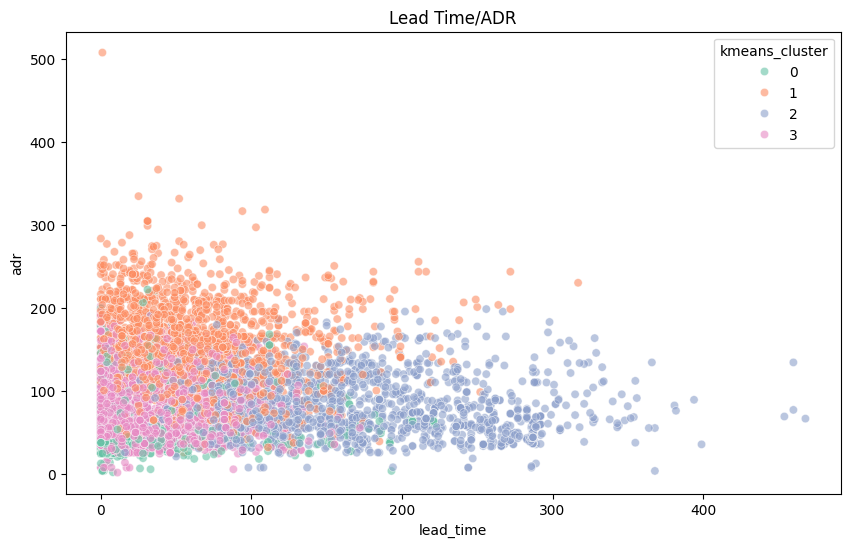

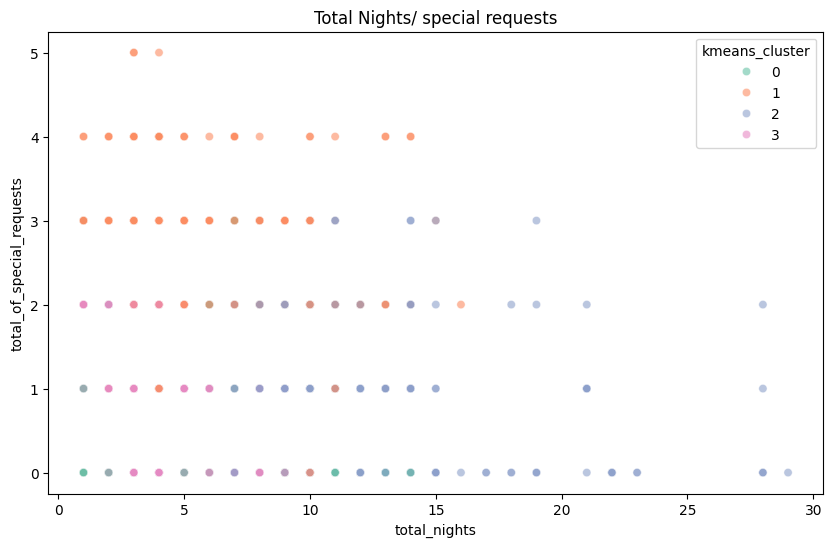

,lead_time,total_nights,adults,adr,total_of_special_requests
kmeans_cluster,,,,,
0,19.29,2.33,1.00,51.17,0.28
1,61.73,5.19,2.09,155.03,1.47
2,170.07,7.77,1.93,82.16,0.49
3,28.88,2.95,2.02,79.07,0.48


In [8]:

k = 4
kmeans = KMeans(
    n_clusters=k,
    random_state=1,
    n_init=10
)

df['kmeans_cluster'] = kmeans.fit_predict(scaled_data)

print(df['kmeans_cluster'].value_counts().sort_index())

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x='lead_time',
    y='adr',
    hue='kmeans_cluster',
    palette='Set2',
    alpha=0.6
)
plt.title("Lead Time/ADR")
plt.show()

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df, x='total_nights', y='total_of_special_requests', hue='kmeans_cluster', palette='Set2', alpha=0.6
)
plt.title("Total Nights/ special requests")
plt.show()
kmeans_summary = df.groupby('kmeans_cluster')[features].mean()
display(kmeans_summary.round(2))


### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose a k value of 4 becuase I didn't want to make it too complicated.

2.for the first cluster it is solo travelers and they stay about 2 nights, the second cluster is customers who spend the most, the third cluster is book the most in advance and stays the longest, and the fourth cluster is people who travel with 2 adults and are average across the board.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
0,0.000000,1.000000,0.000000,4.595390e-07
1,0.000000,0.999999,0.000000,5.799798e-07
2,0.999965,0.000000,0.000000,3.514886e-05
3,0.000494,0.000000,0.999506,1.029246e-07
4,0.999966,0.000000,0.000000,3.430868e-05


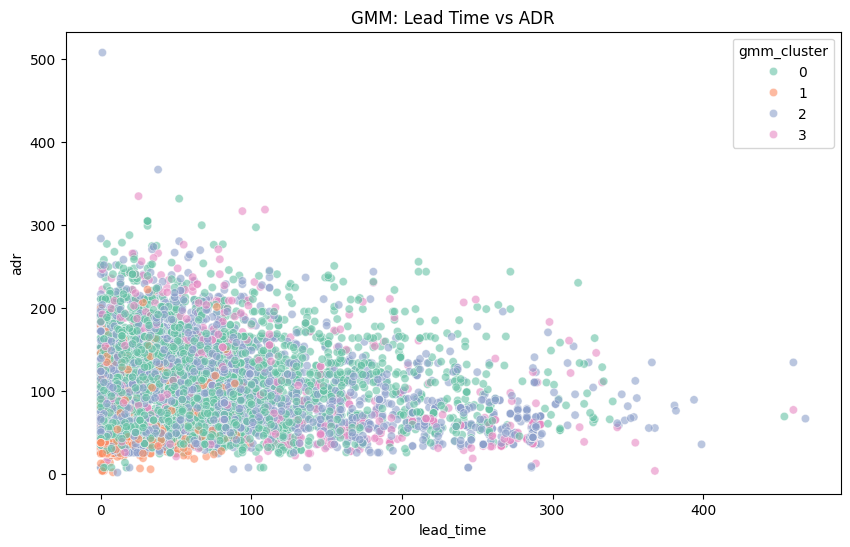

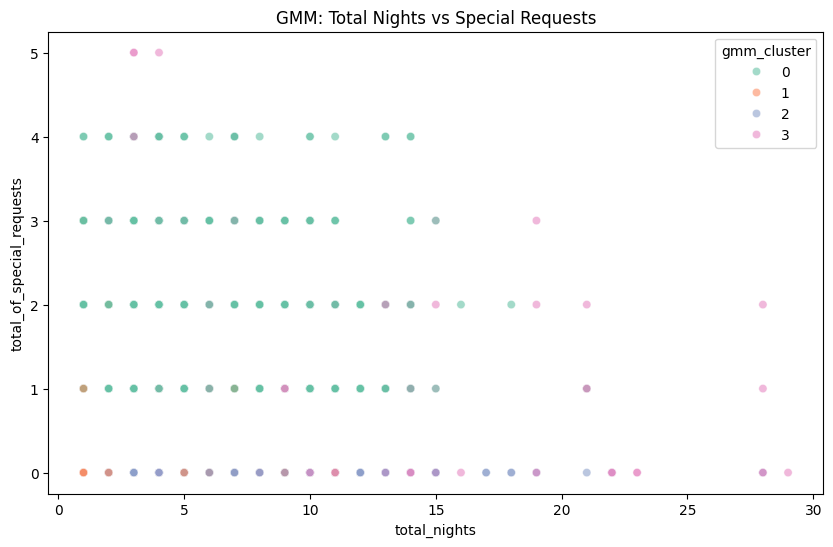

,lead_time,total_nights,adults,adr,total_of_special_requests
gmm_cluster,,,,,
0,68.62,4.71,2.0,106.98,1.45
1,12.30,2.22,1.0,51.61,0.28
2,75.98,4.75,2.0,96.20,0.00
3,116.13,6.36,2.1,110.31,0.90


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture


gmm = GaussianMixture(
    n_components=4,
    random_state=1,
    reg_covar=1e-5
)

gmm.fit(scaled_data)
df['gmm_cluster'] = gmm.predict(scaled_data)
gmm_probabilities = gmm.predict_proba(scaled_data)
probability_df = pd.DataFrame(
    gmm_probabilities,
    columns=['Cluster 0', 'Cluster 1',
             'Cluster 2', 'Cluster 3']
)

display(probability_df.head())
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x='lead_time',
    y='adr',
    hue='gmm_cluster',
    palette='Set2',
    alpha=0.6
)
plt.title("GMM: Lead Time vs ADR")
plt.show()
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x='total_nights',
    y='total_of_special_requests',
    hue='gmm_cluster',
    palette='Set2',
    alpha=0.6
)
plt.title("GMM: Total Nights vs Special Requests")
plt.show()
gmm_summary = df.groupby('gmm_cluster')[features].mean()
display(gmm_summary.round(2))


### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1.

2.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [ ]:
# Add code here 🔧

### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2.

5.3.
I would reccomend Kmeans because its just easier to understand.

## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [10]:

cluster_characteristics = df.groupby('kmeans_cluster').agg(
    customer_count=('lead_time', 'count'),
    avg_lead_time=('lead_time', 'mean'),
    avg_total_nights=('total_nights', 'mean'),
    avg_adults=('adults', 'mean'),
    avg_adr=('adr', 'mean'),
    avg_special_requests=('total_of_special_requests', 'mean')
)

cluster_characteristics = cluster_characteristics.sort_values(
    by='avg_lead_time',
    ascending=False
)

display(cluster_characteristics.round(2))


,customer_count,avg_lead_time,avg_total_nights,avg_adults,avg_adr,avg_special_requests
kmeans_cluster,,,,,,
2,1548,170.07,7.77,1.93,82.16,0.49
1,1884,61.73,5.19,2.09,155.03,1.47
3,2671,28.88,2.95,2.02,79.07,0.48
0,1407,19.29,2.33,1.00,51.17,0.28


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The segments can basically represent different patterns or behaviors with bookings.

2. Depending on which groups spend more/ stay fo rlonger they can get different promotions.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1.
The hardest part was trying to understand the different groups.
2.
I would use clustering when I didn't know the categories ahead of time.
3.
I would explain clustering basically as a way to group together customers who have similary habits.
4.
This helped with my learning outcomes because it helped me use python to solve actual issues.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"